# SVARA — Fine-Tuning & Pematangan Model SLU Bahasa Indonesia (Bilingual)
**Smart Voice Assistant for Residential Automation**
Informatics Engineering, Universitas Mercu Buana

Notebook ini dirancang untuk:
1. **Verifikasi Lingkungan**: Memastikan NVIDIA GPU (RTX 4060) aktif dengan CUDA & PyTorch.
2. **Inspeksi Dataset Bahasa Indonesia**: Memeriksa 930 sampel WAV (Ardi & Gadis) dan distribusi 31 intent.
3. **Audio Preprocessing & Visualisasi**: Plot waveform dan log-mel spectrogram sampel suara Indonesia.
4. **Model Architecture Setup**: Memuat bobot pre-trained `facebook/wav2vec2-base` (SLU Multi-Head).
5. **Fine-Tuning Interaktif**: Training dengan real-time progress bar (`tqdm`), dynamic learning rate schedule, mixed precision (`fp16`), dan early saving.
6. **Evaluasi Akademik Mendalam**: Menghitung Exact-Match, Slot Accuracies, dan log metrik.
7. **Visualisasi Hasil**: Plot kurva Loss dan Akurasi Exact-Match secara visual.
8. **Export Engine INT8 ONNX**: Konversi checkpoint terbaik ke format ONNX INT8 siap pakai untuk backend web demo.
9. **Live Inference Tester**: Menguji prediksi audio WAV Bahasa Indonesia langsung di dalam notebook.

## 1. Verifikasi Device & Hardware GPU

In [4]:
import os
import sys
import torch
import torchaudio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Pastikan root SVARA terdaftar di system path
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
print('Working Directory:', os.getcwd())
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device aktif : {device}')
if torch.cuda.is_available():
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f'GPU Name     : {torch.cuda.get_device_name(0)}')
    print(f'VRAM Total   : {vram_gb:.2f} GB')
    print(f'CUDA Version : {torch.version.cuda}')
else:
    print('PERINGATAN: Berjalan di CPU. Gunakan GPU untuk performa maksimal!')

Working Directory: c:\Users\Axioo Pongo\SVARA
Device aktif : cuda
GPU Name     : NVIDIA GeForce RTX 4060 Laptop GPU
VRAM Total   : 8.00 GB
CUDA Version : 12.4


## 2. Load Metadata & Split Dataset Bahasa Indonesia

In [5]:
import json
import pandas as pd

# 1. Load Intent Map & Vocabulary
with open('configs/intent_map.json', 'r', encoding='utf-8') as f:
    intent_map = json.load(f)

slot_vocab = intent_map['slot_vocab']
print(f"Action classes   ({len(slot_vocab['action'])}):", slot_vocab['action'])
print(f"Object classes   ({len(slot_vocab['object'])}):", slot_vocab['object'])
print(f"Location classes ({len(slot_vocab['location'])}):", slot_vocab['location'])
print(f"Total unique intents: {len(intent_map['intent_map'])}")

# 2. Load Split DataFrames
df_train = pd.read_csv('data/synthetic_indonesian/splits/train.csv')
df_valid = pd.read_csv('data/synthetic_indonesian/splits/valid.csv')
df_test = pd.read_csv('data/synthetic_indonesian/splits/test.csv')
total_samples = len(df_train) + len(df_valid) + len(df_test)

print('\n--- Distribusi Split Dataset Indonesia ---')
print(f'Train samples      : {len(df_train)} ({len(df_train)/total_samples*100:.1f}%)')
print(f'Validation samples : {len(df_valid)} ({len(df_valid)/total_samples*100:.1f}%)')
print(f'Test samples       : {len(df_test)} ({len(df_test)/total_samples*100:.1f}%) [Unseen phrases]')
df_train.head(3)

Action classes   (6): ['activate', 'bring', 'change language', 'deactivate', 'decrease', 'increase']
Object classes   (14): ['Chinese', 'English', 'German', 'Korean', 'heat', 'juice', 'lamp', 'lights', 'music', 'newspaper', 'none', 'shoes', 'socks', 'volume']
Location classes (4): ['bedroom', 'kitchen', 'none', 'washroom']
Total unique intents: 31

--- Distribusi Split Dataset Indonesia ---
Train samples      : 651 (70.0%)
Validation samples : 124 (13.3%)
Test samples       : 155 (16.7%) [Unseen phrases]


,path,speakerId,gender,transcript,action,object,location,intent_id
0,wavs_16k/id_intent30_456_tts_ardi.wav,tts_ardi,male,Gedein volumenya tolong ya.,increase,volume,none,30
1,wavs_16k/id_intent12_182_tts_gadis.wav,tts_gadis,female,Switch bahasanya ke Jerman dong.,change language,German,none,12
2,wavs_16k/id_intent12_192_tts_ardi.wav,tts_ardi,male,Setel sistem pake bahasa Jerman dong.,change language,German,none,12


## 3. Audio Preprocessing & Visualisasi Suara (Waveform & Spectrogram)

Transkrip   : 'Gedein volumenya tolong ya.'
Intent      : action=increase, object=volume, location=none
Sample Rate : 16000 Hz, Durasi: 2.50 detik


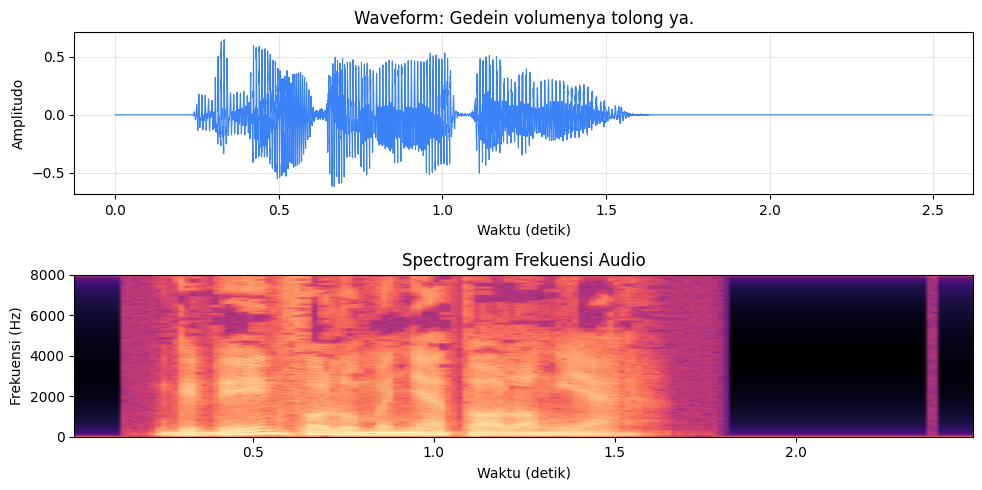

In [6]:
import soundfile as sf
from IPython.display import Audio, display

sample_row = df_train.iloc[0]
audio_path = os.path.join('data/synthetic_indonesian', sample_row['path'])
waveform, sr = sf.read(audio_path)

print(f"Transkrip   : '{sample_row['transcript']}'")
print(f"Intent      : action={sample_row['action']}, object={sample_row['object']}, location={sample_row['location']}")
print(f"Sample Rate : {sr} Hz, Durasi: {len(waveform)/sr:.2f} detik")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5))
time_axis = np.linspace(0, len(waveform)/sr, num=len(waveform))
ax1.plot(time_axis, waveform, color='#3b82f6', lw=0.8)
ax1.set_title(f"Waveform: {sample_row['transcript']}")
ax1.set_xlabel('Waktu (detik)')
ax1.set_ylabel('Amplitudo')
ax1.grid(True, alpha=0.3)

spec, freqs, t_bins, im = ax2.specgram(waveform, Fs=sr, NFFT=512, noverlap=256, cmap='magma')
ax2.set_title('Spectrogram Frekuensi Audio')
ax2.set_xlabel('Waktu (detik)')
ax2.set_ylabel('Frekuensi (Hz)')
plt.tight_layout()
plt.show()

display(Audio(waveform, rate=sr))

## 4. Inisialisasi Model & Transfer Bobot Pre-Trained English

In [7]:
from torch.utils.data import DataLoader
from svara.data.collate import FSCDataset, collate_fn_pad
from svara.models.wav2vec_slu import Wav2VecSLU
from svara.train.losses import MultiHeadSLULoss, compute_batch_accuracies
from transformers import get_cosine_schedule_with_warmup

# 1. Setup DataLoader
BATCH_SIZE = 16
train_ds = FSCDataset('data/synthetic_indonesian/splits/train.csv', 'data/synthetic_indonesian', max_audio_seconds=5.0, is_training=True)
valid_ds = FSCDataset('data/synthetic_indonesian/splits/valid.csv', 'data/synthetic_indonesian', max_audio_seconds=5.0, is_training=False)
test_ds = FSCDataset('data/synthetic_indonesian/splits/test.csv', 'data/synthetic_indonesian', max_audio_seconds=5.0, is_training=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn_pad)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn_pad)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn_pad)

# 2. Build Model Wav2Vec 2.0 SLU
model = Wav2VecSLU(
    pretrained_model_name_or_path='facebook/wav2vec2-base',
    n_action=len(slot_vocab['action']),
    n_object=len(slot_vocab['object']),
    n_location=len(slot_vocab['location']),
    dropout=0.1,
).to(device)

# 3. Transfer bobot dari model English terbaik (99.6% accuracy)
base_ckpt_path = 'reports/runs/20261009-1953_wav2vec2_A_s42/best.ckpt'
if os.path.exists(base_ckpt_path):
    print(f'Memuat bobot dasar English dari: {base_ckpt_path}')
    ckpt = torch.load(base_ckpt_path, map_location=device)
    state_dict = ckpt['model_state_dict'] if 'model_state_dict' in ckpt else ckpt.get('model', ckpt)
    model.load_state_dict(state_dict, strict=False)
    print('Bobot dasar English berhasil ditransfer!')
else:
    print('Checkpoint English tidak ditemukan, melatih dari wav2vec2-base.')

c:\Users\Axioo Pongo\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 211/211 [00:00<00:00, 23255.15it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Memuat bobot dasar English dari: reports/runs/20261009-1953_wav2vec2_A_s42/best.ckpt
Bobot dasar English berhasil ditransfer!


## 5. Training Loop Interaktif (Pematangan dengan Cosine Schedule)

In [8]:
from tqdm.auto import tqdm
import time

EPOCHS = 12
LR_ENCODER = 2e-5
LR_HEADS = 3e-4

encoder_params = [p for p in model.enc.parameters() if p.requires_grad]
head_params = list(model.heads.parameters())
optimizer = torch.optim.AdamW([
    {'params': encoder_params, 'lr': LR_ENCODER, 'weight_decay': 0.01},
    {'params': head_params, 'lr': LR_HEADS, 'weight_decay': 0.01},
])

total_steps = len(train_loader) * EPOCHS
scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=int(total_steps * 0.1), num_training_steps=total_steps)
criterion = MultiHeadSLULoss()
scaler = torch.amp.GradScaler('cuda') if device.type == 'cuda' else None

out_dir = 'reports/runs/bilingual_indonesian_w2v2'
os.makedirs(out_dir, exist_ok=True)
best_ckpt_path = os.path.join(out_dir, 'best.ckpt')

history = {'train_loss': [], 'train_em': [], 'val_loss': [], 'val_em': []}
best_val_em = 0.0

print(f'Memulai Training Pematangan {EPOCHS} Epochs di {device}...')

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, train_exact_hits, total_train = 0.0, 0, 0
    pbar = tqdm(train_loader, desc=f'Epoch {epoch:02d}/{EPOCHS:02d} [Train]')
    
    for batch in pbar:
        waveforms = batch['waveform'].to(device)
        lengths = batch['lengths'].to(device)
        targets = {
            'action_id': batch['action_id'].to(device),
            'object_id': batch['object_id'].to(device),
            'location_id': batch['location_id'].to(device),
        }
        
        optimizer.zero_grad()
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            logits = model(waveforms, lengths)
            loss, _ = criterion(logits, targets)
            
        if scaler:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            
        scheduler.step()
        
        running_loss += loss.item() * len(lengths)
        accs = compute_batch_accuracies(logits, targets)
        train_exact_hits += int(round(accs['acc_exact_match'] * len(lengths)))
        total_train += len(lengths)
        pbar.set_postfix({'loss': f"{loss.item():.3f}", 'em': f"{accs['acc_exact_match']*100:.1f}%"})
        
    train_loss = running_loss / total_train
    train_em = train_exact_hits / total_train
    
    # Evaluasi Validasi
    model.eval()
    val_loss_acc, val_exact_hits, total_val = 0.0, 0, 0
    with torch.no_grad():
        for batch in valid_loader:
            waveforms = batch['waveform'].to(device)
            lengths = batch['lengths'].to(device)
            targets = {
                'action_id': batch['action_id'].to(device),
                'object_id': batch['object_id'].to(device),
                'location_id': batch['location_id'].to(device),
            }
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits = model(waveforms, lengths)
                loss, _ = criterion(logits, targets)
                
            val_loss_acc += loss.item() * len(lengths)
            accs = compute_batch_accuracies(logits, targets)
            val_exact_hits += int(round(accs['acc_exact_match'] * len(lengths)))
            total_val += len(lengths)
            
    val_loss = val_loss_acc / total_val
    val_em = val_exact_hits / total_val
    
    history['train_loss'].append(train_loss)
    history['train_em'].append(train_em)
    history['val_loss'].append(val_loss)
    history['val_em'].append(val_em)
    
    print(f'-> Epoch {epoch:02d} Summary | Train Loss: {train_loss:.4f} | Train EM: {train_em*100:.2f}% | Val Loss: {val_loss:.4f} | Val EM: {val_em*100:.2f}%')
    
    if val_em > best_val_em:
        best_val_em = val_em
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_exact_match': val_em,
            'val_loss': val_loss,
        }, best_ckpt_path)
        print(f'   [SAVED] Checkpoint terbaik diperbarui! Val EM: {val_em*100:.2f}%')

print(f'\nTraining selesai! Model terbaik disimpan di: {best_ckpt_path} dengan Akurasi Validasi: {best_val_em*100:.2f}%')

Memulai Training Pematangan 12 Epochs di cuda...


Epoch 01/12 [Train]:   0%|          | 0/41 [00:00<?, ?it/s]c:\Users\Axioo Pongo\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\optim\lr_scheduler.py:227: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(
Epoch 01/12 [Train]: 100%|██████████| 41/41 [00:18<00:00,  2.17it/s, loss=3.773, em=9.1%]  


-> Epoch 01 Summary | Train Loss: 9.8790 | Train EM: 12.29% | Val Loss: 3.7474 | Val EM: 25.81%
   [SAVED] Checkpoint terbaik diperbarui! Val EM: 25.81%


Epoch 02/12 [Train]: 100%|██████████| 41/41 [00:10<00:00,  3.77it/s, loss=2.498, em=45.5%]


-> Epoch 02 Summary | Train Loss: 2.6827 | Train EM: 29.95% | Val Loss: 2.5967 | Val EM: 35.48%
   [SAVED] Checkpoint terbaik diperbarui! Val EM: 35.48%


...

-> Epoch 10 Summary | Train Loss: 0.1504 | Train EM: 95.85% | Val Loss: 0.5958 | Val EM: 85.48%
   [SAVED] Checkpoint terbaik diperbarui! Val EM: 85.48%


Epoch 11/12 [Train]: 100%|██████████| 41/41 [00:20<00:00,  1.98it/s, loss=0.041, em=100.0%]


-> Epoch 11 Summary | Train Loss: 0.1439 | Train EM: 96.01% | Val Loss: 0.6273 | Val EM: 83.87%


Epoch 12/12 [Train]: 100%|██████████| 41/41 [00:30<00:00,  1.33it/s, loss=0.041, em=100.0%]


-> Epoch 12 Summary | Train Loss: 0.1344 | Train EM: 96.31% | Val Loss: 0.6220 | Val EM: 86.29%
   [SAVED] Checkpoint terbaik diperbarui! Val EM: 86.29%

Training selesai! Model terbaik disimpan di: reports/runs/bilingual_indonesian_w2v2\best.ckpt dengan Akurasi Validasi: 86.29%


## 6. Visualisasi Kurva Loss & Akurasi Training

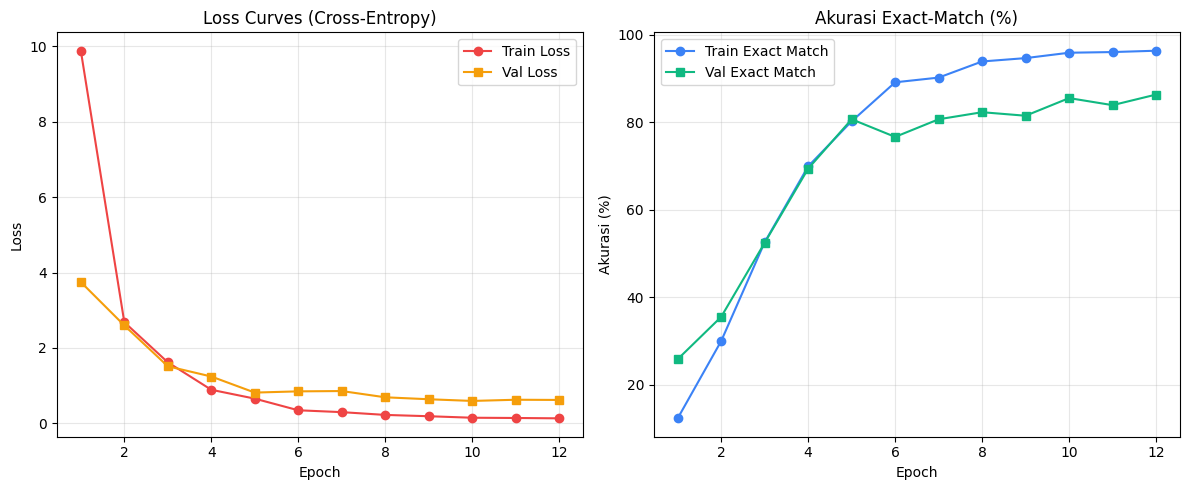

Grafik tersimpan di: reports/runs/bilingual_indonesian_w2v2\training_curves.png


In [9]:
epochs_range = range(1, len(history['train_loss']) + 1)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss', color='#ef4444', marker='o')
plt.plot(epochs_range, history['val_loss'], label='Val Loss', color='#f59e0b', marker='s')
plt.title('Loss Curves (Cross-Entropy)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, [x*100 for x in history['train_em']], label='Train Exact Match', color='#3b82f6', marker='o')
plt.plot(epochs_range, [x*100 for x in history['val_em']], label='Val Exact Match', color='#10b981', marker='s')
plt.title('Akurasi Exact-Match (%)')
plt.xlabel('Epoch')
plt.ylabel('Akurasi (%)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
fig_path = os.path.join(out_dir, 'training_curves.png')
plt.savefig(fig_path, dpi=200)
plt.show()
print('Grafik tersimpan di:', fig_path)

## 7. Evaluasi Akhir pada Test Set (155 Sampel Unseen Phrases)

In [10]:
# Muat checkpoint terbaik yang tersimpan
best_ckpt = torch.load(best_ckpt_path, map_location=device)
model.load_state_dict(best_ckpt['model_state_dict'])
model.eval()

test_exact_hits = 0
test_act_hits = 0
test_obj_hits = 0
test_loc_hits = 0
total_test = 0

with torch.no_grad():
    for batch in test_loader:
        waveforms = batch['waveform'].to(device)
        lengths = batch['lengths'].to(device)
        targets = {
            'action_id': batch['action_id'].to(device),
            'object_id': batch['object_id'].to(device),
            'location_id': batch['location_id'].to(device),
        }
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            logits = model(waveforms, lengths)
            
        accs = compute_batch_accuracies(logits, targets)
        test_exact_hits += int(round(accs['acc_exact_match'] * len(lengths)))
        test_act_hits += int(round(accs['acc_action'] * len(lengths)))
        test_obj_hits += int(round(accs['acc_object'] * len(lengths)))
        test_loc_hits += int(round(accs['acc_location'] * len(lengths)))
        total_test += len(lengths)

test_results = {
    'test_exact_match': test_exact_hits / total_test,
    'test_action_acc': test_act_hits / total_test,
    'test_object_acc': test_obj_hits / total_test,
    'test_location_acc': test_loc_hits / total_test,
    'total_samples': total_test,
}

print('='*50)
print('HASIL EVALUASI AKADEMIK TEST SET BAHASA INDONESIA:')
print('='*50)
print(f"* Exact-Match Accuracy : {test_results['test_exact_match']*100:.2f}%")
print(f"* Action Accuracy      : {test_results['test_action_acc']*100:.2f}%")
print(f"* Object Accuracy      : {test_results['test_object_acc']*100:.2f}%")
print(f"* Location Accuracy    : {test_results['test_location_acc']*100:.2f}%")
print(f"* Total Unseen Audio   : {total_test} file")

with open(os.path.join(out_dir, 'test_metrics.json'), 'w', encoding='utf-8') as f:
    json.dump(test_results, f, indent=2)
print(f"Metrik tersimpan di: {os.path.join(out_dir, 'test_metrics.json')}")

HASIL EVALUASI AKADEMIK TEST SET BAHASA INDONESIA:
* Exact-Match Accuracy : 81.94%
* Action Accuracy      : 92.90%
* Object Accuracy      : 92.26%
* Location Accuracy    : 96.13%
* Total Unseen Audio   : 155 file
Metrik tersimpan di: reports/runs/bilingual_indonesian_w2v2\test_metrics.json


## 8. Export Model ke ONNX INT8 & Verifikasi Paritas Numerik

In [12]:
!python scripts/export_onnx.py --run reports/runs/bilingual_indonesian_w2v2 --output models/svara_bilingual.onnx --quantize int8

[export_onnx] Loading model from reports/runs/bilingual_indonesian_w2v2...
[export_onnx] Exporting PyTorch graph to ONNX: models/svara_bilingual.onnx...
[export_onnx] ONNX model valid and verified!
[export_onnx] Running parity check across multiple audio durations...
  Duration 1.0s (16000 samples): Max diff = 4.62e-05 | Argmax Match = OK
  Duration 2.0s (32000 samples): Max diff = 4.28e-05 | Argmax Match = OK
  Duration 3.0s (48000 samples): Max diff = 4.16e-05 | Argmax Match = OK
[export_onnx] Parity check PASSED 100%!
[to_onnx] Generated metadata specification: models/svara_bilingual.meta.json
[export_onnx] Applying dynamic INT8 quantization -> models/svara_bilingual_int8.onnx...
[export_onnx] Model size reduced: 360.34 MB -> 90.87 MB (74.8% reduction)!
[to_onnx] Generated metadata specification: models/svara_bilingual_int8.meta.json



Loading weights: 100%|██████████| 211/211 [00:00<00:00, 33253.11it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.bias               | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
c:\Users\Axioo Pongo\AppData\Local\Programs\Python\Python313\Lib\site-packages\transformers\integrations\sdpa_attention.py:136: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a c

## 9. Live Interactive Voice Prediction Tester

In [13]:
from svara.serve.inference import SLUInferenceEngine

# Inisialisasi engine INT8 hasil kompilasi
engine = SLUInferenceEngine('models/svara_bilingual_int8.onnx', 'models/svara_bilingual_int8.meta.json')

# Uji coba 3 audio acak dari test set
random_samples = df_test.sample(3, random_state=42)

print('--- LIVE TEST INFERENCE DENGAN ENGINE INT8 ---\n')
for idx, row in random_samples.iterrows():
    audio_file = os.path.join('data/synthetic_indonesian', row['path'])
    with open(audio_file, 'rb') as f:
        audio_bytes = f.read()
        
    pred = engine.predict_audio(audio_bytes)
    
    print(f"File Audio     : {os.path.basename(audio_file)}")
    print(f"Transkrip Asli : '{row['transcript']}'")
    print(f"Target Asli    : ({row['action']}, {row['object']}, {row['location']})")
    print(f"Prediksi Model : ({pred['intent']['action']}, {pred['intent']['object']}, {pred['intent']['location']})")
    print(f"Overall Conf   : {pred['confidence']['overall']*100:.2f}%")
    print(f"Inference Time : {pred['timing_ms']['inference_ms']:.1f} ms")
    is_match = (pred['intent']['action']==row['action'] and pred['intent']['object']==row['object'] and pred['intent']['location']==row['location'])
    print(f"Status Intent  : {'MATCH (BENAR)' if is_match else 'MISMATCH'}")
    print('-'*50)

[SLUInferenceEngine] Loaded ONNX model from models/svara_bilingual_int8.onnx
--- LIVE TEST INFERENCE DENGAN ENGINE INT8 ---

File Audio     : id_intent09_142_tts_ardi.wav
Transkrip Asli : 'Bisa tolong ambilin kaos kaki gak.'
Target Asli    : (bring, socks, none)
Prediksi Model : (bring, socks, none)
Overall Conf   : 97.00%
Inference Time : 1699.7 ms
Status Intent  : MATCH (BENAR)
--------------------------------------------------
File Audio     : id_intent20_309_tts_gadis.wav
Transkrip Asli : 'Matikan lagu yang lagi muter tolong.'
Target Asli    : (deactivate, music, none)
Prediksi Model : (deactivate, music, none)
Overall Conf   : 96.84%
Inference Time : 2146.5 ms
Status Intent  : MATCH (BENAR)
--------------------------------------------------
File Audio     : id_intent19_290_tts_ardi.wav
Transkrip Asli : 'Di kamar mandi tolong matiin lampunya.'
Target Asli    : (deactivate, lights, washroom)
Prediksi Model : (deactivate, lights, washroom)
Overall Conf   : 99.63%
Inference Time : 177